In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

In [2]:
df = pd.read_csv("../data/bank_note_dataset.csv")

In [3]:
def remove_all_outliers_from_column(df,threshold=1.5):
    df_clean = df.copy()
    numeric_cols = df.select_dtypes(include=["float64","int64"]).columns

    for col in numeric_cols:
        Q1 = df[col].quantile(0.25)
        Q3 = df[col].quantile(0.75)
        IQR = Q3 - Q1

        lower_bound = Q1 - threshold * IQR
        upper_bound = Q3 + threshold * IQR

        df_clean = df_clean[ (df_clean[col] >= lower_bound) &  (df_clean[col] <= upper_bound)]

    return df_clean.copy()

In [4]:
df_new = remove_all_outliers_from_column(df)

In [5]:
X = df_new.drop("Class",axis=1)
y = df_new["Class"]

In [6]:
from sklearn.model_selection import train_test_split

In [7]:
X_temp,X_test,y_temp,y_test = train_test_split(X,y,test_size=0.15,random_state=15)

In [8]:
X_train, X_val, y_train, y_val = train_test_split(X_temp, y_temp,test_size=0.1765,random_state=15)

In [9]:
from tensorflow.keras.models import Sequential

In [10]:
from tensorflow.keras.layers import Input,Dense,Dropout

In [11]:
from sklearn.preprocessing import StandardScaler

In [12]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_val = scaler.transform(X_val)
X_test = scaler.transform(X_test)

In [13]:
model = Sequential()
model.add(Input(shape=(4,)))
model.add(Dense(32,activation="relu"))
model.add(Dropout(0.24))
model.add(Dense(16,activation="relu"))
model.add(Dropout(0.20))
model.add(Dense(1,activation="sigmoid"))

In [14]:
model.compile(optimizer='adam',loss="binary_crossentropy",metrics=["accuracy"])

In [15]:
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ dense (Dense)                        │ (None, 32)                  │             160 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout (Dropout)                    │ (None, 32)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_1 (Dense)                      │ (None, 16)                  │             528 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dropout_1 (Dropout)                  │ (None, 16)                  │               0 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ dense_2 (Dense)                      │ (None, 1)                   │              17 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 705 (2.75 KB)

 Trainable params: 705 (2.75 KB)

 Non-trainable params: 0 (0.00 B)

In [16]:
from tensorflow.keras.callbacks import EarlyStopping

In [17]:
early_stopping = EarlyStopping(
    monitor="val_loss",
    patience=10,
    restore_best_weights=True
)

In [18]:
history = model.fit(X_train,y_train,epochs=35,batch_size=32,validation_data=[X_val,y_val],callbacks=[early_stopping])

Epoch 1/35
23/23 ━━━━━━━━━━━━━━━━━━━━ 5s 49ms/step - accuracy: 0.6194 - loss: 0.6568 - val_accuracy: 0.8065 - val_loss: 0.6016
Epoch 2/35
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - accuracy: 0.8042 - loss: 0.5800 - val_accuracy: 0.8581 - val_loss: 0.5271
Epoch 3/35
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8361 - loss: 0.5140 - val_accuracy: 0.9161 - val_loss: 0.4456
Epoch 4/35
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.8736 - loss: 0.4425 - val_accuracy: 0.9226 - val_loss: 0.3618
Epoch 5/35
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9194 - loss: 0.3688 - val_accuracy: 0.9355 - val_loss: 0.2768
Epoch 6/35
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 18ms/step - accuracy: 0.9125 - loss: 0.3005 - val_accuracy: 0.9742 - val_loss: 0.2057
Epoch 7/35
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - accuracy: 0.9444 - loss: 0.2293 - val_accuracy: 0.9806 - val_loss: 0.1526
Epoch 8/35
23/23 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - accuracy: 0.9458 - loss: 0.1909 - val_accuracy: 0.9806 - v

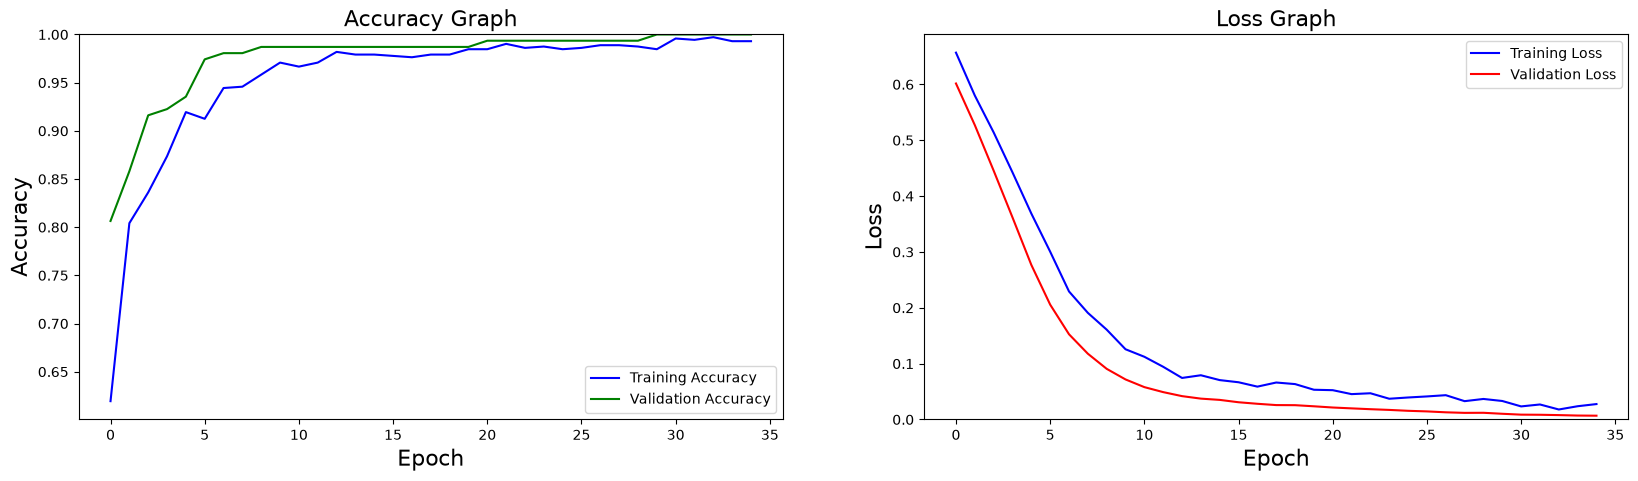

In [19]:
plt.figure(figsize=(20,5))
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], color='b', label="Training Accuracy")
# FIX: Moved val_accuracy here where it belongs!
if 'val_accuracy' in history.history:
    plt.plot(history.history['val_accuracy'], color='g', label="Validation Accuracy")
plt.legend(loc="lower right")
plt.xlabel('Epoch', fontsize=16)
plt.ylabel('Accuracy', fontsize=16)
plt.ylim([min(plt.ylim()), 1])
plt.title("Accuracy Graph", fontsize=16)

# ------------------------ Graphic 2 LOSS --------------------------------

plt.subplot(1,2,2)
plt.plot(history.history['loss'], color='b', label='Training Loss')
# FIX: Changed 'val_accuracy' to 'val_loss' to match the Loss Graph
if 'val_loss' in history.history:
    plt.plot(history.history['val_loss'], color='r', label='Validation Loss')
plt.legend(loc="upper right")
plt.xlabel('Epoch', fontsize=16)
plt.ylabel('Loss', fontsize=16)
plt.ylim([0, max(plt.ylim())])
plt.title("Loss Graph", fontsize=16)

plt.show()

In [20]:
loss, acc = model.evaluate(X_test,y_test, verbose=False)
print("Test Accuracy: %.1f%%" % (100.0 * acc))
print("Test Loss: %.1f%%" % (100.0 * loss))

Test Accuracy: 100.0%
Test Loss: 0.9%


In [21]:
#???